In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score


In [18]:
# nltk.download('averaged_perceptron_tagger')
# nltk.download('averaged_perceptron_tagger_eng')
# nltk.download('punkt')
# nltk.download('stopwords')
# nltk.download('wordnet')
# nltk.download('omw-1.4')


## Dataset Check

In [19]:
data = pd.read_csv('combined_dataset_final_with_urgency.csv')
print(data.head())


                            Genre  \
0                 Online learning   
1            Athletics and sports   
2  Academic Support and Resources   
3               Food and Cantines   
4               Food and Cantines   

                                             Reports  Age   Gpa  Year  Count  \
0          The classroom projectors doesnt work well   26  2.80     2      1   
1   The athletic department should prioritize the...   22  2.98     4      1   
2  The library catalogue system is outdated and h...   22  0.93     3      1   
3  The canteen does not display any allergen info...   16  1.72     5      1   
4  The dining area near the science block has no ...   18  1.72     4      1   

  Gender   Nationality Urgency  
0      M      Malaysia     Low  
1      M        Soudan     Low  
2      F         India     Low  
3      F       Nigeria     Low  
4      M  Saudi Arabia     Low  


In [20]:
print(data.shape)
print(data.info())


(6225, 9)
<class 'pandas.DataFrame'>
RangeIndex: 6225 entries, 0 to 6224
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Genre        6225 non-null   str    
 1   Reports      6225 non-null   str    
 2   Age          6225 non-null   int64  
 3   Gpa          6225 non-null   float64
 4   Year         6225 non-null   int64  
 5   Count        6225 non-null   int64  
 6   Gender       6225 non-null   str    
 7   Nationality  6225 non-null   str    
 8   Urgency      6225 non-null   str    
dtypes: float64(1), int64(3), str(5)
memory usage: 1.3 MB
None


In [21]:
# Dropping unused columns
cols_to_drop = ['Age', 'Gpa', 'Year', 'Count', 'Gender', 'Nationality']
data = data.drop(columns=cols_to_drop)
data.head()


,Genre,Reports,Urgency
0,Online learning,The classroom projectors doesnt work well,Low
1,Athletics and sports,The athletic department should prioritize the...,Low
2,Academic Support and Resources,The library catalogue system is outdated and h...,Low
3,Food and Cantines,The canteen does not display any allergen info...,Low
4,Food and Cantines,The dining area near the science block has no ...,Low


In [22]:
# Duplicate check
# print(f"Number of duplicates: {data.duplicated().sum()}")
# data = data.drop_duplicates().reset_index(drop=True)
# print(f"Rows after dropping duplicates: {len(data)}")


In [23]:
# Standardize genre labels (must be applied consistently to ANY dataset used later,
# including the unseen test set below — this was a bug in the previous notebook)
def standardize_genre(df):
    df = df.copy()
    df['Genre'] = df['Genre'].replace('Activities and Travelling', 'Student Activities')
    df['Genre'] = df['Genre'].replace('Career opportunities', 'Internship Opportunities')
    return df

data = standardize_genre(data)
print(data['Genre'].value_counts())


Genre
Academic Support and Resources       691
Housing and Transportation           660
Athletics and sports                 590
Health and Well-being Support        585
Internship Opportunities             572
Student Activities                   571
International student experiences    567
Online learning                      536
Student Affairs                      515
Financial Support                    505
Food and Cantines                    433
Name: count, dtype: int64


## EDA

Genre distribution:
Genre
Academic Support and Resources       691
Housing and Transportation           660
Athletics and sports                 590
Health and Well-being Support        585
Internship Opportunities             572
Student Activities                   571
International student experiences    567
Online learning                      536
Student Affairs                      515
Financial Support                    505
Food and Cantines                    433
Name: count, dtype: int64

Total records: 6225
Total genres: 11


C:\Users\rmksu\AppData\Local\Temp\ipykernel_17528\2909608096.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=genre_counts.values, y=genre_counts.index, palette='viridis')


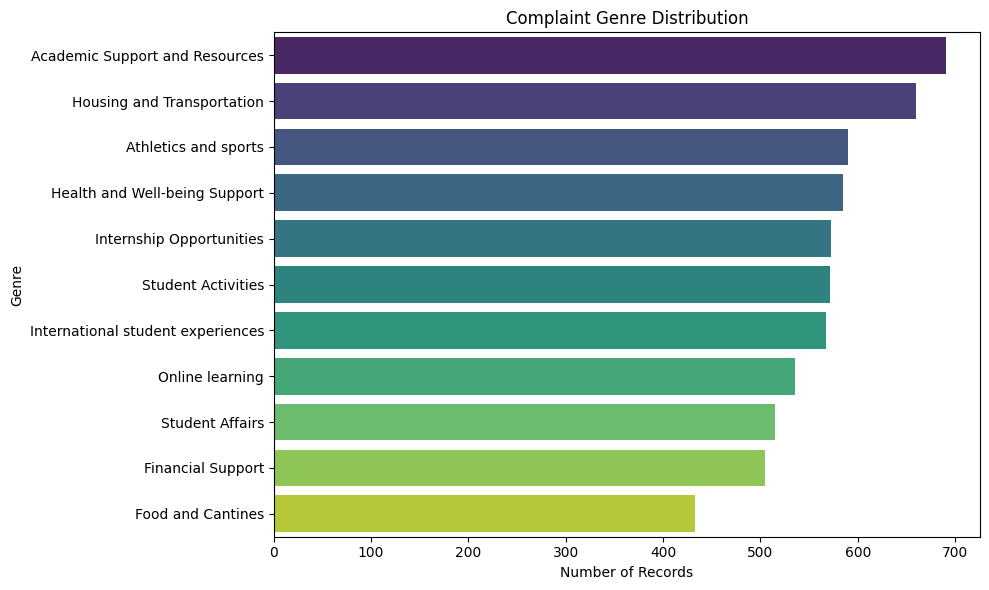

In [24]:
genre_counts = data['Genre'].value_counts()
print("Genre distribution:")
print(genre_counts)
print(f"\nTotal records: {len(data)}")
print(f"Total genres: {data['Genre'].nunique()}")

plt.figure(figsize=(10, 6))
sns.barplot(x=genre_counts.values, y=genre_counts.index, palette='viridis')
plt.title('Complaint Genre Distribution')
plt.xlabel('Number of Records')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()


In [25]:
x = data['Reports']
y = data['Genre']

# 80/20 split, stratified so every genre is represented proportionally
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)


## Preprocessing

In [26]:
lemmatizer = WordNetLemmatizer()

def get_label(tag):
    if tag.startswith('j'):
        return 'a'
    elif tag.startswith('r') or tag.startswith('v') or tag.startswith('n'):
        return tag[0]
    else:
        return 'a'

def lemmatizing(word_list):
    lemma_list = []
    tagged = pos_tag(word_list)
    for word, tag in tagged:
        label = get_label(tag.lower())
        if label:
            result = lemmatizer.lemmatize(word, label)
            lemma_list.append(result)
        else:
            result = lemmatizer.lemmatize(word)
            lemma_list.append(result)
    return lemma_list

def preprocessing(sentence):
    eng_stopwords = set(stopwords.words('english'))
    punctuations = set(string.punctuation)

    sentence = sentence.lower()
    word_list = word_tokenize(sentence)

    filtered = [
        token for token in word_list
        if token not in eng_stopwords
        and token not in punctuations
        and token.isalpha()
    ]

    return lemmatizing(filtered)


Model Training

In [27]:
tfidf_params = dict(
    tokenizer=preprocessing,
    ngram_range=(1, 2),
    max_features=5000,
    min_df=3,
    max_df=0.85,
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(**tfidf_params)),
    ("clf", LinearSVC(
        C=0.1,
        max_iter=5000,
        class_weight="balanced"
    ))
])

model.fit(x_train, y_train)


C:\Users\rmksu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\feature_extraction\text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.85, max_features=5000, min_df=3,
                                 ngram_range=(1, 2),
                                 tokenizer=<function preprocessing at 0x000002524009ACA0>)),
                ('clf',
                 LinearSVC(C=0.1, class_weight='balanced', max_iter=5000))])

In [28]:
# Internal test set performance
y_pred = model.predict(x_test)
print("[Test Set Report]")
print(classification_report(y_test, y_pred))

train_f1 = f1_score(y_train, model.predict(x_train), average="macro")
test_f1  = f1_score(y_test, y_pred, average="macro")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, x_train, y_train, cv=skf, scoring="f1_macro")
cv_mean = cv_scores.mean()
gap = train_f1 - cv_mean

print(f"\nTrain F1 (macro): {train_f1:.4f}")
print(f"CV F1   (macro): {cv_mean:.4f}  (+/- {cv_scores.std():.4f})")
print(f"Test F1 (macro): {test_f1:.4f}")
print(f"Overfit Gap (Train-CV): {gap:.4f}  " + ("<-- Good" if gap < 0.05 else "<-- Borderline" if gap < 0.10 else "<-- Overfitting"))


[Test Set Report]
                                   precision    recall  f1-score   support

   Academic Support and Resources       0.92      0.86      0.89       138
             Athletics and sports       0.98      1.00      0.99       118
                Financial Support       0.86      0.89      0.87       101
                Food and Cantines       0.97      1.00      0.98        87
    Health and Well-being Support       0.95      0.96      0.95       117
       Housing and Transportation       0.84      0.92      0.88       132
International student experiences       0.98      0.98      0.98       113
         Internship Opportunities       0.97      1.00      0.98       115
                  Online learning       0.93      0.93      0.93       107
               Student Activities       1.00      0.98      0.99       114
                  Student Affairs       0.91      0.76      0.83       103

                         accuracy                           0.93      1245
     

C:\Users\rmksu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\feature_extraction\text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
C:\Users\rmksu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\feature_extraction\text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
C:\Users\rmksu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\feature_extraction\text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
C:\Users\rmksu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\


Train F1 (macro): 0.9780
CV F1   (macro): 0.9369  (+/- 0.0064)
Test F1 (macro): 0.9336
Overfit Gap (Train-CV): 0.0411  <-- Good


In [29]:
# Unseen test set (1000 held-out complaints)
# IMPORTANT: apply the same standardize_genre() step used on the training data,
# otherwise label mismatches will tank the score artificially (this was a bug before).
test_data = pd.read_csv('test_dataset_1000.csv')
test_data = standardize_genre(test_data)

x_test_new = test_data['Reports']
y_test_new = test_data['Genre']

y_pred_new = model.predict(x_test_new)
print("[Unseen Test Set Report]")
print(classification_report(y_test_new, y_pred_new))

acc = accuracy_score(y_test_new, y_pred_new)
f1_new = f1_score(y_test_new, y_pred_new, average="macro")
print(f"Accuracy: {acc:.4f}")
print(f"Macro F1: {f1_new:.4f}")


[Unseen Test Set Report]
                                   precision    recall  f1-score   support

   Academic Support and Resources       0.81      0.81      0.81        90
             Athletics and sports       0.86      1.00      0.92        91
                Financial Support       0.95      0.93      0.94        92
                Food and Cantines       0.97      1.00      0.98        92
    Health and Well-being Support       0.94      0.94      0.94        90
       Housing and Transportation       0.96      0.88      0.92        91
International student experiences       0.89      0.90      0.90        90
         Internship Opportunities       0.87      1.00      0.93        92
                  Online learning       0.82      0.91      0.86        92
               Student Activities       1.00      0.77      0.87        90
                  Student Affairs       0.76      0.64      0.70        90

                         accuracy                           0.89      100

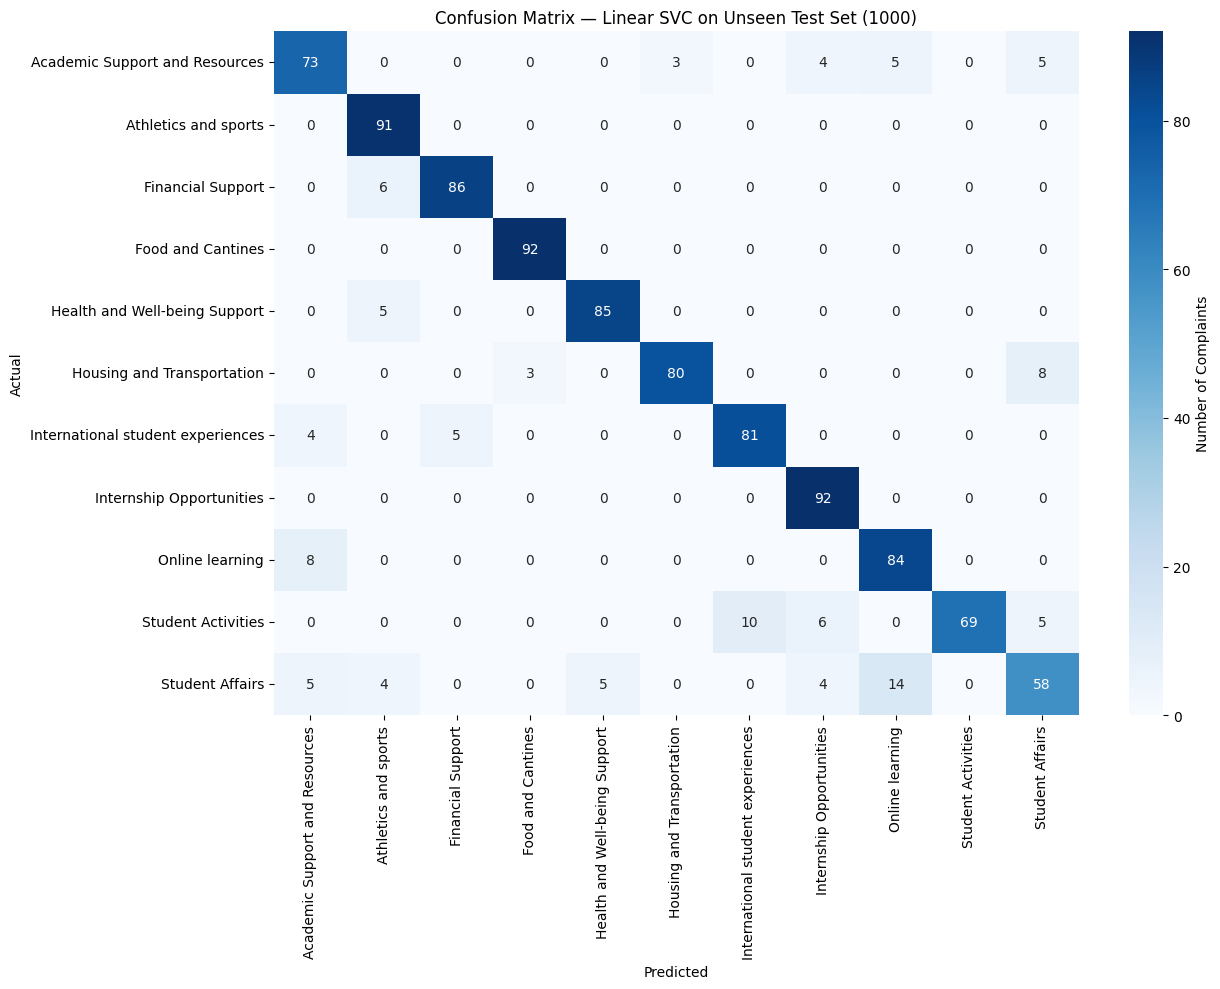

In [30]:
labels_order = sorted(y_test_new.unique())
cm = confusion_matrix(y_test_new, y_pred_new, labels=labels_order)

plt.figure(figsize=(13, 10))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=labels_order, yticklabels=labels_order,
    cbar_kws={'label': 'Number of Complaints'}
)
plt.title('Confusion Matrix — Linear SVC on Unseen Test Set (1000)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()


## Urgency Scoring

Every complaint gets a score from **1 to 10**:

| Score | Level | Meaning |
|---|---|---|
| 1–3 | Minor | General dissatisfaction, suggestions |
| 4–7 | Moderate | Something broken, delayed, or ignored |
| 8–10 | High | Safety, harassment, or health crisis |

The score starts at 1 and adds points for each signal found: safety/crisis words (+7, so any match lands in High), explicit urgency wording (+2), something broken (+2), a long-running problem (+1), a complaint that was ignored (+1), emotional intensity such as `!` or shouting (+1), and a small bonus for categories where delays hurt students more (+1). The result is capped at 10.

In [ ]:
import re

# Each group adds its weight once if any of its patterns appear in the complaint
URGENCY_RULES = [
    # Safety, harassment, health crisis -> any match lands in High (1 + 7 = 8)
    (7, "safety/crisis", [
        r"\bharass(ment|ed|ing)?\b", r"\bassault(ed)?\b", r"\babus(e|ed|ive)\b",
        r"\bthreat(s|en|ened|ening)?\b", r"\bviolen(ce|t)\b", r"\bstalk(ing|ed|er)?\b",
        r"\bfire\b", r"\binjur(y|ed|ies)\b", r"\bunsafe\b", r"\bdanger(ous)?\b",
        r"\bemergency\b", r"\bself[- ]harm\b", r"\bsuicid", r"\bcrisis\b",
        r"\bbleeding\b", r"\bfaint(ed)?\b", r"\bfood poisoning\b",
    ]),
    # Explicit urgency wording
    (2, "urgent wording", [
        r"\burgent(ly)?\b", r"\bimmediate(ly)?\b", r"\basap\b", r"\bright now\b",
        r"\btoday\b", r"\bdeadline\b",
    ]),
    # Something is broken / unusable
    (2, "breakdown", [
        r"\bbroken\b", r"\bnot working\b", r"\bdoesn'?t work\b", r"\bdown\b",
        r"\bunavailable\b", r"\bglitch(y|es)?\b", r"\bcrash(es|ed|ing)?\b",
        r"\bleak(s|ing)?\b", r"\bno (water|electricity|power|internet|wifi)\b",
        r"\bcan'?t (access|submit|log ?in|enter)\b",
    ]),
    # Problem has dragged on / been ignored
    (1, "prolonged", [
        r"\bweeks?\b", r"\bmonths?\b", r"\brepeatedly\b", r"\bagain\b",
        r"\bstill\b", r"\bdelay(ed|s)?\b", r"\bconstantly\b", r"\bkeeps? happening\b",
    ]),
    # Already reported but nobody acted on it
    (1, "ignored", [
        r"\bno (response|reply|resolution|action)\b", r"\bignored\b",
        r"\bnever (been )?fixed\b", r"\bhasn'?t been (fixed|resolved|addressed)\b",
    ]),
]

# Small bump for categories where delays tend to hurt students more
CATEGORY_BONUS = {
    "Health and Well-being Support": 1,
    "Student Affairs": 1,
    "Financial Support": 1,
}

COMPILED = [(w, name, re.compile("|".join(p), re.IGNORECASE)) for w, name, p in URGENCY_RULES]

def urgency_level(score: int) -> str:
    if score >= 8:
        return "High"
    if score >= 4:
        return "Moderate"
    return "Minor"

def score_urgency(text: str, category: str = None) -> dict:
    """Return an urgency score from 1 to 10, its level, and what triggered it."""
    if not isinstance(text, str) or not text.strip():
        return {"score": 1, "level": "Minor", "reasons": []}

    score, reasons = 1, []
    for weight, name, pattern in COMPILED:
        if pattern.search(text):
            score += weight
            reasons.append(name)

    # Emotional intensity: exclamation marks or shouted words
    if "!" in text or any(w.isupper() and len(w) > 2 for w in text.split()):
        score += 1
        reasons.append("intensity")

    if category in CATEGORY_BONUS:
        score += CATEGORY_BONUS[category]
        reasons.append("category")

    score = max(1, min(10, score))
    return {"score": score, "level": urgency_level(score), "reasons": reasons}


In [ ]:
# Score distribution across the dataset
scored = data.apply(lambda r: score_urgency(r['Reports'], r['Genre']), axis=1)
data['UrgencyScore'] = scored.apply(lambda r: r['score'])
data['UrgencyLevel'] = scored.apply(lambda r: r['level'])

print(data['UrgencyLevel'].value_counts())

fig, ax = plt.subplots(figsize=(9, 4))
counts = data['UrgencyScore'].value_counts().reindex(range(1, 11), fill_value=0)
colors = ['#4C9F70'] * 3 + ['#E0A030'] * 4 + ['#C8453B'] * 3
ax.bar(counts.index, counts.values, color=colors)
ax.set_xticks(range(1, 11))
ax.set_xlabel('Urgency score')
ax.set_ylabel('Number of complaints')
ax.set_title('Urgency Score Distribution (green = Minor, amber = Moderate, red = High)')
plt.tight_layout()
plt.show()

# A few examples of the highest-scoring complaints
pd.set_option('display.max_colwidth', 120)
print(data.sort_values('UrgencyScore', ascending=False)[['UrgencyScore', 'UrgencyLevel', 'Reports']].head(8).to_string(index=False))


Department Routing

In [ ]:
department_map = {
    "Academic Support and Resources":     "Academic Affairs Office",
    "Athletics and sports":               "Sports & Recreation Center",
    "Financial Support":                  "Finance / Scholarship Office",
    "Food and Cantines":                  "Campus Services (Food & Facilities)",
    "Health and Well-being Support":      "Health & Counseling Center",
    "Housing and Transportation":         "Facilities & Housing Office",
    "International student experiences":  "International Student Office",
    "Internship Opportunities":           "Career Center",
    "Online learning":                    "IT / Learning Management Support",
    "Student Activities":                 "Student Activities Office",
    "Student Affairs":                    "Student Affairs Office",
}

def classify_and_route(complaint: str):
    """
    Classify a student complaint with Linear SVC, score its urgency (1-10),
    and route it to the responsible department.
    Usage: classify_and_route("your complaint here")
    """
    if not complaint.strip():
        print("Please enter a complaint.")
        return

    pred = model.predict([complaint])[0]
    dept = department_map.get(pred, "General Office (unmapped category)")
    urgency = score_urgency(complaint, pred)

    print()
    print("=" * 55)
    print("  YOUR COMPLAINT:")
    print(f"  {complaint}")
    print("-" * 55)
    print(f"  Predicted Category: {pred}")
    print(f"  Urgency:            {urgency['score']}/10 ({urgency['level']})")
    print(f"  Routed To:          {dept}")
    print("=" * 55)
    print()

    return {
        "category": pred,
        "department": dept,
        "urgency_score": urgency["score"],
        "urgency_level": urgency["level"],
    }


In [ ]:
# Try it out
examples = [
    "The gym isn't cleaned regularly.",
    "My internship application isn't accepted yet.",
    "My lecture room is very dirty.",
    "My assignments can't be submitted on time due to app lag.",
    "The library chair is broken for months now, why hasn't it been fixed yet?",
    "My scholarship payment is still delayed for weeks with no response.",
    "The LMS is down and I can't submit my assignment before the deadline today!",
    "A senior keeps harassing me after class and I feel unsafe.",
]
results = [classify_and_route(c) for c in examples]


In [ ]:
# Staff priority queue: highest urgency first, grouped by department
queue = pd.DataFrame(results)
queue['complaint'] = examples
queue = queue.sort_values(['urgency_score'], ascending=False)
print(queue[['urgency_score', 'urgency_level', 'department', 'complaint']].to_string(index=False))
